# Minimax — Adversário da rede

Neste notebook vamos definir o Minimax, conferir uma jogada e executar os modos médio e difícil. O código das funções é o mesmo de `minimax.py`.

Escolha o kernel da `.venv` e execute as células na ordem. As dependências estão em `t2/apoio/requirements-notebook.txt`.

In [1]:
from pathlib import Path
import sys
import json
from html import escape
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, display

# Localiza o projeto mesmo abrindo o notebook pela pasta do algoritmo.
pasta_atual = Path.cwd().resolve()
raiz = next((p for p in [pasta_atual, *pasta_atual.parents] if (p / "t2" / "app.py").is_file()), None)
if raiz is None:
    raise FileNotFoundError("Abra o notebook dentro do repositório.")
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from functools import lru_cache
from t2.apoio.jogo import result
import csv
pasta_algoritmo = raiz / "t2" / "algoritmos" / "minimax"

def salvar_grafico(figura, nome):
    # Salva uma cópia do gráfico junto do algoritmo.
    figura.savefig(pasta_algoritmo / nome, dpi=150, bbox_inches="tight")

def salvar_csv(nome, linhas):
    with (pasta_algoritmo / nome).open("w", newline="", encoding="utf-8") as arquivo:
        escritor = csv.DictWriter(arquivo, fieldnames=list(linhas[0]))
        escritor.writeheader()
        escritor.writerows(linhas)


In [2]:
def mostrar_tabela(colunas, linhas):
    cabecalho = "".join(f"<th style='padding:8px;text-align:left'>{escape(str(c))}</th>" for c in colunas)
    corpo = "".join("<tr>" + "".join(f"<td style='padding:8px;border-top:1px solid #ddd'>{escape(str(v))}</td>" for v in linha) + "</tr>" for linha in linhas)
    display(HTML(f"<table><thead><tr>{cabecalho}</tr></thead><tbody>{corpo}</tbody></table>"))

## Minimax completo

A avaliação usa a perspectiva do jogador da vez, na forma Negamax. Quando mais de uma jogada tem o melhor valor, a função retorna todas. Para jogar, o desempate usa o menor índice.

In [3]:
@lru_cache(maxsize=None)
def minimax(board, player):
    """
    Calcula o valor do tabuleiro para o jogador da vez e retorna as melhores casas.
    Na hora de jogar, usamos a de menor índice quando há empate entre elas.
    """
    end = result(board)
    if end is not None:
        return end * player, ()
    scores = []
    for i, value in enumerate(board):
        if value == 0:
            child = list(board)
            child[i] = player
            score, _ = minimax(tuple(child), -player)
            scores.append((-score, i))
    best = max(s for s, _ in scores)
    return best, tuple(i for s, i in scores if s == best)

## Médio e difícil

O difícil sempre usa Minimax. No médio, a cada turno há 50% de chance de uma jogada aleatória válida. O sorteio acontece antes de chamar o Minimax, sem mudar a busca.

In [4]:
def opponent_move(board, player, mode, rng):
    available = [i for i,v in enumerate(board) if v == 0]
    if mode == 'medio' and rng.random() < .5:
        return int(rng.choice(available))
    return minimax(tuple(board), player)[1][0]

## Conferir uma posição

No tabuleiro abaixo, é a vez de X. Vamos olhar o valor da posição e as casas que têm a melhor avaliação.

In [5]:
tabuleiro = [1, 1, 0, -1, -1, 0, 0, 0, 0]
jogador = 1
valor, melhores = minimax(tuple(tabuleiro), jogador)
mostrar_tabela(["Casa", "Ocupação"], [[i+1, v] for i, v in enumerate(tabuleiro)])
print("Valor para quem está na vez:", valor)
print("Melhores casas:", [i+1 for i in melhores])
rng = np.random.default_rng(42)
print("Jogada no difícil:", opponent_move(tabuleiro, jogador, "dificil", rng)+1)

Casa,Ocupação
1,1
2,1
3,0
4,-1
5,-1
6,0
7,0
8,0
9,0


Valor para quem está na vez: 1
Melhores casas: [3]
Jogada no difícil: 3


## Valor de cada jogada disponível

Para cada casa livre, simulamos a jogada e avaliamos o estado resultante pelo Minimax. O valor é mostrado pela perspectiva de quem está jogando: 1 para vitória, 0 para empate e -1 para derrota, considerando a continuação ótima dos dois lados. As casas já ocupadas ficam identificadas por X ou O.

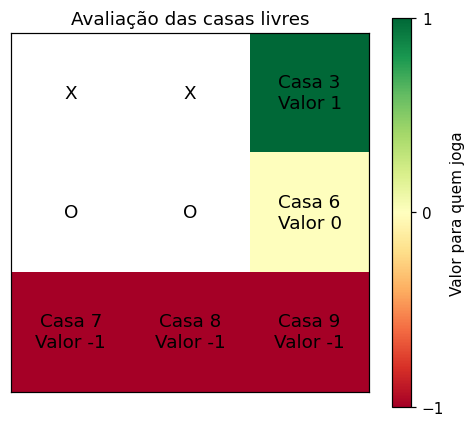

In [6]:
valores = np.full(9, np.nan)
for casa, ocupacao in enumerate(tabuleiro):
    if ocupacao == 0:
        proximo = tabuleiro.copy()
        proximo[casa] = jogador
        valores[casa] = -minimax(tuple(proximo), -jogador)[0]
fig, eixo = plt.subplots(figsize=(4.5, 4))
mapa = eixo.imshow(np.ma.masked_invalid(valores.reshape(3, 3)), cmap="RdYlGn", vmin=-1, vmax=1)
for casa, ocupacao in enumerate(tabuleiro):
    legenda = "X" if ocupacao == 1 else "O" if ocupacao == -1 else f"Casa {casa+1}\nValor {valores[casa]:.0f}"
    eixo.text(casa%3, casa//3, legenda, ha="center", va="center", fontsize=12)
eixo.set(title="Avaliação das casas livres", xticks=[], yticks=[])
fig.colorbar(mapa, ax=eixo, ticks=[-1, 0, 1], label="Valor para quem joga")
fig.tight_layout()
salvar_grafico(fig, "minimax_jogadas.png")
plt.show()
plt.close(fig)

## Sorteios no modo médio

Repetimos a escolha no mesmo tabuleiro para observar o modo médio. Uma jogada aleatória também pode coincidir com uma jogada ótima. Portanto, olhar só a casa escolhida não revela qual caminho do sorteio foi usado.

In [7]:
rng = np.random.default_rng(42)
mostrar_tabela(["Tentativa", "Casa escolhida no médio"], [
    [i+1, opponent_move(tabuleiro, jogador, "medio", rng)+1] for i in range(20)
])

Tentativa,Casa escolhida no médio
1,3
2,7
3,3
4,9
5,3
6,3
7,3
8,9
9,7
10,3


## Escolhas dos modos médio e difícil

Repetimos a escolha no mesmo tabuleiro para observar a diferença entre os modos. A rede não participa deste exemplo. No difícil, o desempate é fixo. No médio, o sorteio pode levar a casas diferentes, mas uma escolha aleatória também pode coincidir com a melhor casa.

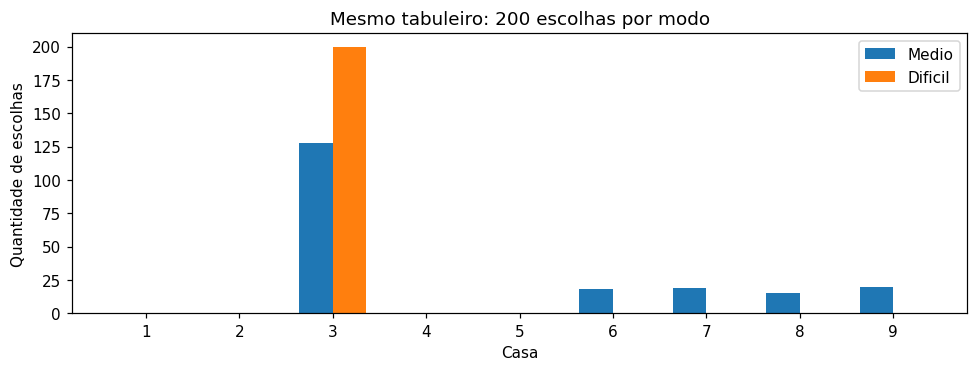

Modo,Escolhas ótimas,Total
medio,128,200
dificil,200,200


In [8]:
tabuleiro_exemplo = [1, 1, 0, -1, -1, 0, 0, 0, 0]
repeticoes = 200
frequencias = {}
for modo in ["medio", "dificil"]:
    rng = np.random.default_rng(42)
    escolhas = [opponent_move(tabuleiro_exemplo, 1, modo, rng) for _ in range(repeticoes)]
    frequencias[modo] = np.bincount(escolhas, minlength=9)
fig, eixo = plt.subplots(figsize=(9, 3.5))
x = np.arange(1, 10)
for i, (modo, contagens) in enumerate(frequencias.items()):
    eixo.bar(x+(i-0.5)*0.36, contagens, 0.36, label=modo.capitalize())
eixo.set(title=f"Mesmo tabuleiro: {repeticoes} escolhas por modo", xlabel="Casa", ylabel="Quantidade de escolhas", xticks=x)
eixo.legend()
fig.tight_layout()
salvar_grafico(fig, "minimax_escolhas.png")
plt.show()
plt.close(fig)
melhores_exemplo = minimax(tuple(tabuleiro_exemplo), 1)[1]
mostrar_tabela(["Modo", "Escolhas ótimas", "Total"], [
    [modo, int(sum(contagens[i] for i in melhores_exemplo)), repeticoes]
    for modo, contagens in frequencias.items()
])

## Partida completa

Aqui os dois jogadores usam Minimax difícil. O controle de vitória e empate continua sendo feito pelas regras do jogo. Depois podemos mudar o modo de um deles para observar outra partida.

In [9]:
tabuleiro = [0]*9
jogador = 1
rng = np.random.default_rng(42)
modos = {1: "dificil", -1: "dificil"}
jogadas = []
while result(tabuleiro) is None:
    casa = opponent_move(tabuleiro, jogador, modos[jogador], rng)
    tabuleiro[casa] = jogador
    jogadas.append([len(jogadas)+1, "X" if jogador == 1 else "O", casa+1])
    jogador *= -1
mostrar_tabela(["Jogada", "Jogador", "Casa"], jogadas)
print("Resultado:", {1: "X venceu", -1: "O venceu", 0: "Empate"}[result(tabuleiro)])

Jogada,Jogador,Casa
1,X,1
2,O,5
3,X,2
4,O,3
5,X,7
6,O,4
7,X,6
8,O,8
9,X,9


Resultado: Empate


## Partidas contra um jogador aleatório

Este experimento olha o Minimax separado da rede. O adversário escolhe apenas casas livres aleatórias, e alternamos quem começa. Nesse caso faz sentido repetir o difícil: o outro jogador muda os caminhos da partida. É diferente de repetir a mesma rede determinística contra o mesmo Minimax.

Os números deste gráfico são desse experimento auxiliar e não substituem os resultados de treinamento da MLP.

Modo,Vitórias,Empates,Derrotas
medio,58,19,23
dificil,88,12,0


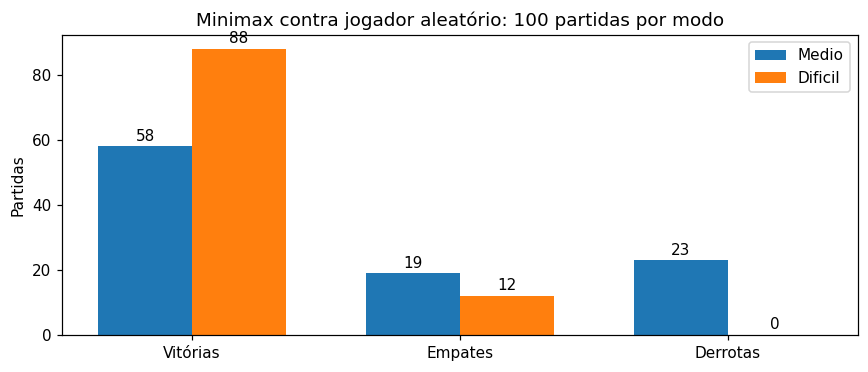

In [10]:
partidas_por_modo = 100
resumo_modos = {}
for modo in ["medio", "dificil"]:
    resumo = {"Vitórias": 0, "Empates": 0, "Derrotas": 0}
    for partida in range(partidas_por_modo):
        rng = np.random.default_rng(42+partida)
        casas = [0]*9
        vez = 1
        simbolo_ia = 1 if partida%2 == 0 else -1
        while result(casas) is None:
            if vez == simbolo_ia:
                casa = opponent_move(casas, vez, modo, rng)
            else:
                casa = int(rng.choice([i for i, v in enumerate(casas) if v == 0]))
            casas[casa] = vez
            vez *= -1
        fim = result(casas)
        resumo["Empates" if fim == 0 else "Vitórias" if fim == simbolo_ia else "Derrotas"] += 1
    resumo_modos[modo] = resumo
mostrar_tabela(["Modo", "Vitórias", "Empates", "Derrotas"], [[modo, *r.values()] for modo, r in resumo_modos.items()])
fig, eixo = plt.subplots(figsize=(8, 3.5))
x = np.arange(3)
for i, (modo, r) in enumerate(resumo_modos.items()):
    barras = eixo.bar(x+(i-0.5)*0.35, list(r.values()), 0.35, label=modo.capitalize())
    eixo.bar_label(barras, padding=2)
eixo.set(title="Minimax contra jogador aleatório: 100 partidas por modo", ylabel="Partidas", xticks=x, xticklabels=["Vitórias", "Empates", "Derrotas"])
eixo.legend()
fig.tight_layout()
salvar_grafico(fig, "minimax_resultados.png")
plt.show()
plt.close(fig)

## Uso no treinamento

Durante a avaliação, a rede joga contra esse adversário e alternamos quem começa. No médio são necessárias várias partidas por causa da aleatoriedade. No difícil determinístico, usamos uma partida para cada posição inicial.

O ciclo completo fica em [genetico.ipynb](../genetico/genetico.ipynb). Os arquivos `.py` são os usados pelo jogo. Alterações feitas nas células não modificam automaticamente esses arquivos.

## Arquivos na pasta do algoritmo

Os gráficos mostrados acima também são salvos em PNG nesta pasta. Os números vão para arquivos CSV, junto do código e do notebook, como no T1. Rodar as células novamente atualiza esses arquivos com a execução atual.


In [11]:
salvar_csv("minimax_resultados.csv", [
    {"modo": modo, **r} for modo, r in resumo_modos.items()
])
salvar_csv("minimax_escolhas.csv", [
    {"casa": i+1, "medio": int(frequencias["medio"][i]), "dificil": int(frequencias["dificil"][i])}
    for i in range(9)
])
print("Arquivos PNG e CSV em:", pasta_algoritmo.relative_to(raiz))


Arquivos PNG e CSV em: t2/algoritmos/minimax
